# Tema 7, Exercițiul 1
## Estimarea dimensiunii unei populații (captură-recaptură)

### Notații

- $N$: efectivul total al populației (parametrul necunoscut);
- $M = 20$: animale marcate la prima capturare;
- $n = 15$: animale selectate la a doua capturare;
- $Y = 4$: dintre cele $n$ recapturate, câte sunt marcate (observația);
- model: $Y \mid N \sim \text{Hypergeometric}(N, M, n)$, prior $N \sim \text{DiscreteUniform}(20, 200)$.

Numărul de marcați dintr-o extragere fără revenire de $n$ animale dintr-o populație cu $M$ marcați și $N - M$ nemarcați este hipergeometric; priorul uniform discret exprimă că, înainte de date, orice efectiv între $20$ și $200$ este la fel de plauzibil.

PyMC: `chains=4`, `draws=2000` per lanț (`tune=2000`), `random_seed=42`.

## a) Modelul în PyMC și distribuția a posteriori a lui $N$

`N` este populația totală, `k` numărul de succese din populație (marcații $M$) și `n` mărimea extragerii.

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

M, n, Y = 20, 15, 4        # marcati, recapturati, marcati-recapturati
N_lo, N_hi = 20, 200       # suportul priorului DiscreteUniform

with pm.Model() as model:
    N = pm.DiscreteUniform("N", lower=N_lo, upper=N_hi)
    pm.HyperGeometric("Y", N=N, k=M, n=n, observed=Y)
    idata = pm.sample(2000, tune=2000, chains=4, random_seed=42)

Multiprocess sampling (4 chains in 4 jobs)


Metropolis: [N]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


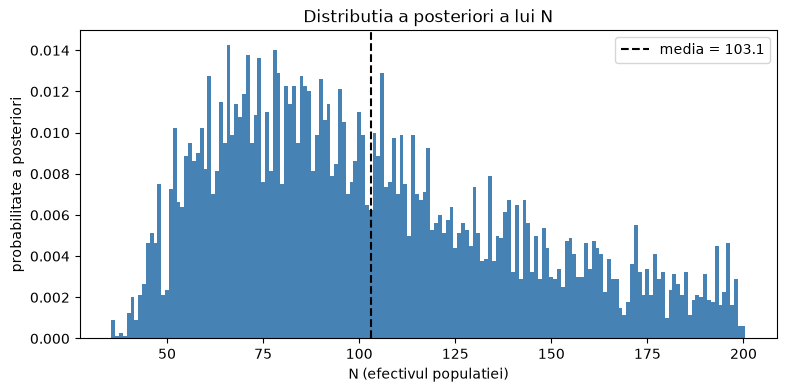

In [ ]:
# esantioanele a posteriori ale lui N, aplatizate peste lanturi
N_post = idata.posterior["N"].stack(s=("chain", "draw")).values

valori, frecvente = np.unique(N_post, return_counts=True)
prob_post = frecvente / frecvente.sum()

plt.figure(figsize=(9, 4))
plt.bar(valori, prob_post, width=1.0, color="steelblue")
plt.axvline(N_post.mean(), color="black", ls="--", label=f"media = {N_post.mean():.1f}")
plt.xlabel("N (efectivul populatiei)")
plt.ylabel("probabilitate a posteriori")
plt.title("Distributia a posteriori a lui N")
plt.legend()
plt.show()

## b) Media, mediana, HDI 95% și comparația cu $Mn/Y$

In [ ]:
media = N_post.mean()
mediana = np.median(N_post)
hdi_lo, hdi_hi = az.hdi(N_post, prob=0.95)
clasic = M * n / Y

print(f"media a posteriori = {media:.2f}")
print(f"mediana a posteriori = {mediana:.1f}")
print(f"HDI 95% = [{hdi_lo:.0f}, {hdi_hi:.0f}]")
print(f"estimare clasica Mn/Y = {clasic:.1f}")

media a posteriori = 103.07
mediana a posteriori = 95.0
HDI 95% = [41, 179]
estimare clasica Mn/Y = 75.0


Estimarea clasică $Mn/Y = 75$ coincide aproximativ cu mediana a posteriori, dar media a posteriori este mai mare pentru că posteriorul este asimetric la dreapta. HDI de 95% este larg: cu doar $Y = 4$ marcați, incertitudinea despre $N$ rămâne mare.

## c) Probabilitatea a posteriori $P(N > 100 \mid Y = 4)$

Este fracțiunea de eșantioane a posteriori cu $N > 100$.

In [ ]:
p_peste_100 = (N_post > 100).mean()
print(f"P(N > 100 | Y=4) = {p_peste_100:.4f}")

P(N > 100 | Y=4) = 0.4542


Aproximativ $45\%$ din masa a posteriori se află peste $100$ de animale: datele nu pot discrimina clar între o populație mică și una mare, din nou din cauza eșantionului mic.

## d) Distribuția predictivă a posteriori a numărului de marcați la o nouă capturare

Pentru o nouă extragere de $n = 15$ animale (marcajele rămân neschimbate), numărul de marcați $\tilde Y$ se obține integrând verosimilitatea hipergeometrică peste incertitudinea a posteriori a lui $N$:

$$P(\tilde Y = y \mid Y = 4) = \sum_N P(\tilde Y = y \mid N)\, P(N \mid Y = 4).$$

Sampling: [Y]


Output()

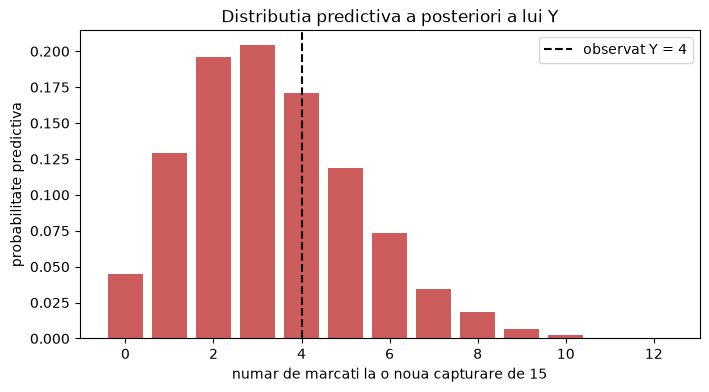

media predictiva = 3.33 marcati
interval observat frecvent: 0 .. 8


In [ ]:
with model:
    pp = pm.sample_posterior_predictive(idata, random_seed=42)

Yrep = pp.posterior_predictive["Y"].stack(s=("chain", "draw")).values

vals, cnts = np.unique(Yrep, return_counts=True)
plt.figure(figsize=(8, 4))
plt.bar(vals, cnts / cnts.sum(), width=0.8, color="indianred")
plt.axvline(Y, color="black", ls="--", label=f"observat Y = {Y}")
plt.xlabel("numar de marcati la o noua capturare de 15")
plt.ylabel("probabilitate predictiva")
plt.title("Distributia predictiva a posteriori a lui Y")
plt.legend()
plt.show()

print(f"media predictiva = {Yrep.mean():.2f} marcati")
print(f"interval observat frecvent: {np.percentile(Yrep, 2.5):.0f} .. {np.percentile(Yrep, 97.5):.0f}")

### Diferența față de posteriorul lui $N$

Posteriorul lui $N$ descrie incertitudinea despre un **parametru** (efectivul populației, un întreg mare). Distribuția predictivă descrie o **observație viitoare** $\tilde Y \in \{0, \dots, 15\}$ adică numărul de marcați la o nouă capturare.

Ea combină două surse de incertitudine: cea despre $N$ și aleatoriul extragerii hipergeometrice. De aceea este centrată în jurul valorii observate $Y = 4$ și nu seamănă cu forma posteriorului lui $N$.